Upload the zip file to colab

In [1]:
from google.colab import files

uploaded = files.upload()

Saving Data set.zip to Data set.zip


Extract the dataset

In [2]:
import zipfile

with zipfile.ZipFile("Data set.zip", "r") as zip_ref:
    zip_ref.extractall("/Data_set")

Check that everything is there

In [3]:
import os

dataset_path = "/Data_set/Data set"

print(os.listdir(dataset_path))
print(os.listdir(dataset_path + "/Training"))
print(os.listdir(dataset_path + "/Testing"))

['Testing', 'Training']
['glioma', 'meningioma', 'pituitary', 'notumor']
['glioma', 'meningioma', 'pituitary', 'notumor']


In [4]:
print(os.getcwd())
print(os.listdir("/Data_set/Data set/Testing"))

/content
['glioma', 'meningioma', 'pituitary', 'notumor']


In [5]:
print(os.listdir("/Data_set/Data set/Training"))

['glioma', 'meningioma', 'pituitary', 'notumor']


**Data Preprocessing**

Step 1 — Check corrupted/unreadable images

In [6]:
from PIL import Image


dataset_path = "/Data_set/Data set"

classes = ["glioma", "meningioma", "pituitary", "notumor"]

def check_images(split):
    bad_images = []

    for cls in classes:
        folder = os.path.join(dataset_path, split, cls)

        for filename in os.listdir(folder):
            filepath = os.path.join(folder, filename)

            try:
                with Image.open(filepath) as img:
                    img.verify()
            except Exception:
                bad_images.append(filepath)

    return bad_images


bad_training = check_images("Training")
bad_testing = check_images("Testing")

print("Bad training images:", len(bad_training))
print("Bad testing images:", len(bad_testing))

Bad training images: 0
Bad testing images: 0


Step 2 : Checking the class distribution

In [7]:
classes = ["glioma", "meningioma", "pituitary", "notumor"]

for split in ["Training", "Testing"]:
    print(f"\n{split}")
    print("-" * 30)

    for cls in classes:
        folder = os.path.join(dataset_path, split, cls)
        count = len(os.listdir(folder))
        print(f"{cls}: {count}")


Training
------------------------------
glioma: 1400
meningioma: 1400
pituitary: 1400
notumor: 1400

Testing
------------------------------
glioma: 400
meningioma: 400
pituitary: 400
notumor: 400


# Before deciding on resizing, normalization, augmentation, or even the model input format, we should first characterize the raw images.

Image dimensions — e.g. 512×512, 300×400, etc.

Number of channels — RGB, grayscale, RGBA, etc.

Image formats — JPG, PNG, etc.

Pixel-value range

Aspect-ratio distribution

Class-wise image counts — already checked

Corrupted images — already checked

In [8]:
from PIL import Image
import os
from collections import Counter

dataset_path = "/Data_set/Data set"

classes = ["glioma", "meningioma", "pituitary", "notumor"]

def analyze_images(split):

    sizes = Counter()
    modes = Counter()
    formats = Counter()

    total_images = 0

    for cls in classes:

        folder = os.path.join(dataset_path, split, cls)

        for filename in os.listdir(folder):

            filepath = os.path.join(folder, filename)

            try:
                with Image.open(filepath) as img:

                    total_images += 1

                    # Image dimensions
                    sizes[img.size] += 1

                    # RGB, L (grayscale), RGBA, etc.
                    modes[img.mode] += 1

                    # JPG, PNG, etc.
                    formats[img.format] += 1

            except Exception:
                pass

    return total_images, sizes, modes, formats


for split in ["Training", "Testing"]:

    total, sizes, modes, formats = analyze_images(split)

    print("\n" + "=" * 50)
    print(split)
    print("=" * 50)

    print("Total images:", total)

    print("\nImage modes:")
    for mode, count in modes.items():
        print(f"{mode}: {count}")

    print("\nImage formats:")
    for fmt, count in formats.items():
        print(f"{fmt}: {count}")

    print("\nNumber of unique image sizes:", len(sizes))

    print("\nMost common image sizes:")
    for size, count in sizes.most_common(10):
        print(f"{size}: {count}")


Training
Total images: 5600

Image modes:
L: 2358
RGB: 3238
RGBA: 3
P: 1

Image formats:
JPEG: 5596
PNG: 4

Number of unique image sizes: 381

Most common image sizes:
(512, 512): 4012
(225, 225): 253
(630, 630): 69
(201, 251): 40
(236, 236): 39
(442, 442): 38
(150, 198): 33
(228, 221): 32
(232, 217): 32
(428, 417): 31

Testing
Total images: 1600

Image modes:
RGB: 891
L: 709

Image formats:
JPEG: 1600

Number of unique image sizes: 203

Most common image sizes:
(512, 512): 1002
(225, 225): 85
(630, 630): 21
(228, 221): 19
(227, 222): 19
(232, 217): 18
(201, 251): 17
(200, 252): 14
(300, 168): 13
(256, 256): 11


Before resizing images in to the same dimensions we want to look in to the aspect ratio

In [9]:
from PIL import Image
import os
import numpy as np

dataset_path = "/Data_set/Data set"

classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "notumor"
]

def get_aspect_ratios(split):

    aspect_ratios = []

    for cls in classes:

        folder = os.path.join(dataset_path, split, cls)

        for filename in os.listdir(folder):

            filepath = os.path.join(folder, filename)

            try:
                with Image.open(filepath) as img:

                    width, height = img.size

                    aspect_ratio = width / height

                    aspect_ratios.append(aspect_ratio)

            except Exception:
                pass

    return aspect_ratios


for split in ["Training", "Testing"]:

    ratios = get_aspect_ratios(split)

    print("\n" + "=" * 50)
    print(split)
    print("=" * 50)

    print("Number of images:", len(ratios))
    print("Minimum:", min(ratios))
    print("Maximum:", max(ratios))
    print("Mean:", np.mean(ratios))
    print("Median:", np.median(ratios))
    print("Std:", np.std(ratios))


Training
Number of images: 5600
Minimum: 0.644808743169399
Maximum: 1.7857142857142858
Mean: 0.9884351556534875
Median: 1.0
Std: 0.07929330130401531

Testing
Number of images: 1600
Minimum: 0.7169811320754716
Maximum: 1.7857142857142858
Mean: 0.9941241920027886
Median: 1.0
Std: 0.1256382671439496


In the training dataset the mean is 0.9884 and the median is 1.0 and in the testing dataset the mean is 0.994 and the median is 1.0 so i think the existing aspect ratios are good

Croping the image dataset

In [10]:
!pip install imutils

import cv2
import numpy as np
import imutils
from PIL import Image


def crop_img(img):
    """
    Remove unnecessary background/margins from a brain MRI.

    Based on the preprocessing method provided by the
    dataset author.
    """

    # OpenCV loads images as BGR
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Smooth the image
    gray = cv2.GaussianBlur(gray, (3, 3), 0)

    # Threshold
    thresh = cv2.threshold(
        gray,
        45,
        255,
        cv2.THRESH_BINARY
    )[1]

    # Remove small noise
    thresh = cv2.erode(
        thresh,
        None,
        iterations=2
    )

    thresh = cv2.dilate(
        thresh,
        None,
        iterations=2
    )

    # Find external contours
    cnts = cv2.findContours(
        thresh.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cnts = imutils.grab_contours(cnts)

    # If no contour is found, return original image
    if len(cnts) == 0:
        return img.copy()

    # Largest contour
    c = max(cnts, key=cv2.contourArea)

    # Extreme points
    extLeft = tuple(c[c[:, :, 0].argmin()][0])
    extRight = tuple(c[c[:, :, 0].argmax()][0])
    extTop = tuple(c[c[:, :, 1].argmin()][0])
    extBot = tuple(c[c[:, :, 1].argmax()][0])

    # No additional pixels, same as author's ADD_PIXELS = 0
    ADD_PIXELS = 0

    # Image dimensions
    h, w = img.shape[:2]

    # Make sure crop coordinates stay inside image
    x1 = max(extLeft[0] - ADD_PIXELS, 0)
    x2 = min(extRight[0] + ADD_PIXELS, w)

    y1 = max(extTop[1] - ADD_PIXELS, 0)
    y2 = min(extBot[1] + ADD_PIXELS, h)

    # Crop
    new_img = img[y1:y2, x1:x2].copy()

    return new_img

Test croping

In [11]:
import os

folder = "/Data_set/Data set/Training/glioma"

files = os.listdir(folder)

print(files[:10])

['Tr-gl_1028.jpg', 'Tr-gl_1249.jpg', 'Tr-gl_344.jpg', 'Tr-gl_862.jpg', 'Tr-gl_600.jpg', 'Tr-gl_1085.jpg', 'Tr-gl_674.jpg', 'Tr-gl_756.jpg', 'Tr-gl_283.jpg', 'Tr-gl_156.jpg']


In [12]:
import os
import cv2
from tqdm import tqdm

# Original dataset
dataset_path = "/Data_set/Data set"

# New dataset for cropped images
cropped_path = "/Data_set/Cropped"

classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "notumor"
]

splits = [
    "Training",
    "Testing"
]


for split in splits:

    for cls in classes:

        # Input folder
        input_folder = os.path.join(
            dataset_path,
            split,
            cls
        )

        # Output folder
        output_folder = os.path.join(
            cropped_path,
            split,
            cls
        )

        # Create output folder
        os.makedirs(
            output_folder,
            exist_ok=True
        )

        # Get all files
        files = os.listdir(input_folder)

        print(f"\nProcessing {split}/{cls}")
        print("Images:", len(files))

        # Process every image
        for filename in tqdm(files):

            input_path = os.path.join(
                input_folder,
                filename
            )

            output_path = os.path.join(
                output_folder,
                filename
            )

            # Read image
            image = cv2.imread(input_path)

            # Check if image was readable
            if image is None:
                print("Could not read:", input_path)
                continue

            # Crop margins
            cropped = crop_img(image)

            # Save cropped image
            cv2.imwrite(
                output_path,
                cropped
            )

print("\nCropping completed!")


Processing Training/glioma
Images: 1400


100%|██████████| 1400/1400 [00:04<00:00, 288.36it/s]



Processing Training/meningioma
Images: 1400


100%|██████████| 1400/1400 [00:04<00:00, 339.62it/s]



Processing Training/pituitary
Images: 1400


100%|██████████| 1400/1400 [00:04<00:00, 283.06it/s]


... (7 outputs left out)

100%|██████████| 400/400 [00:01<00:00, 311.93it/s]



Processing Testing/notumor
Images: 400


100%|██████████| 400/400 [00:00<00:00, 628.82it/s]


Cropping completed!


Display original vs cropped

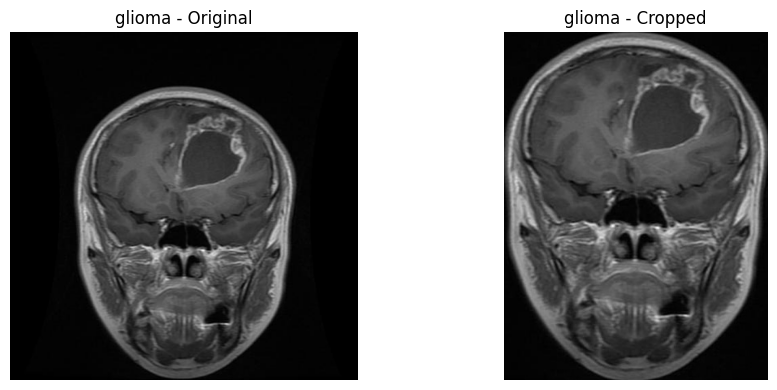

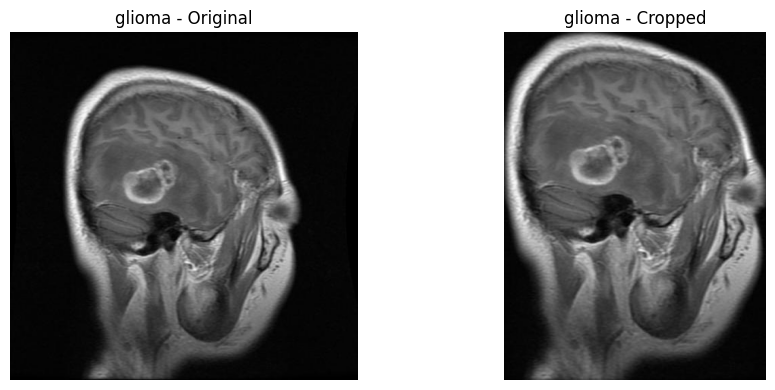

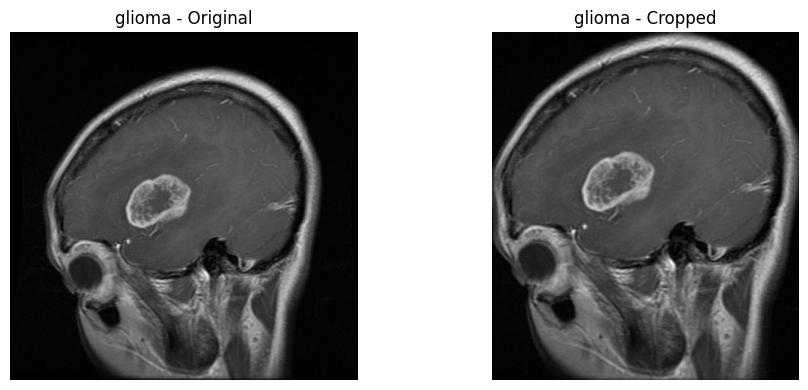

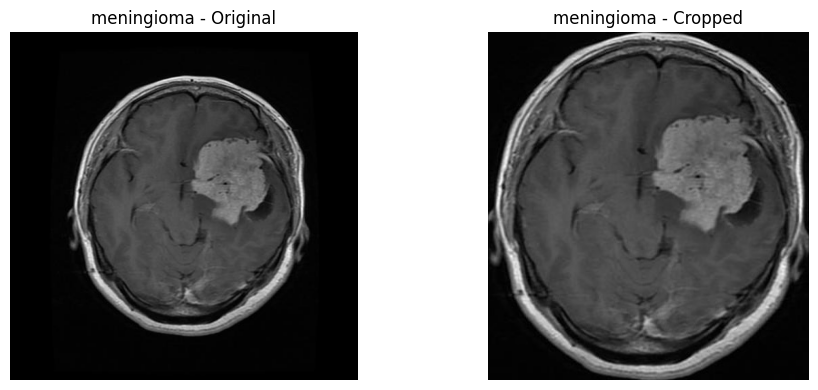

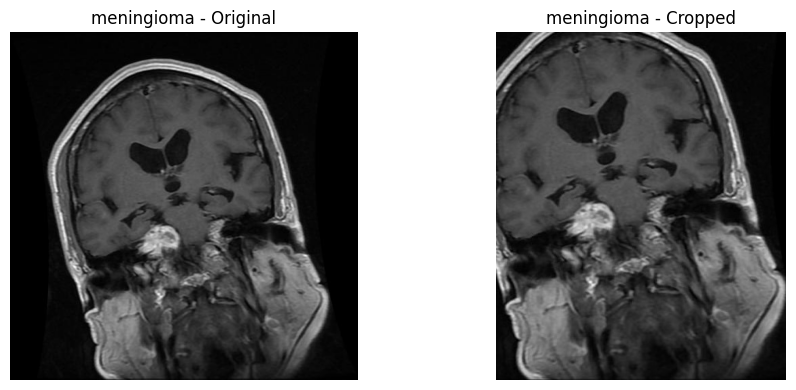

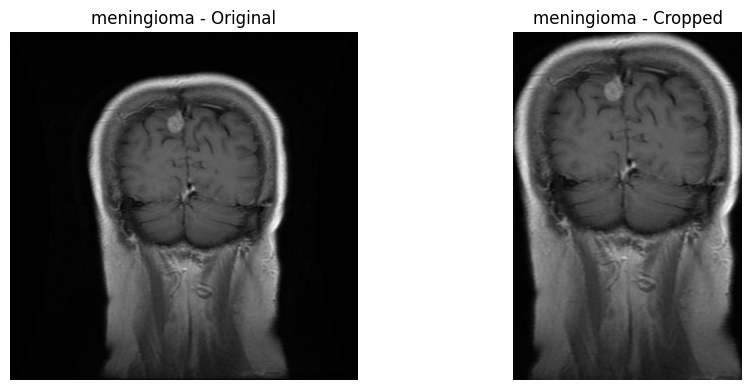

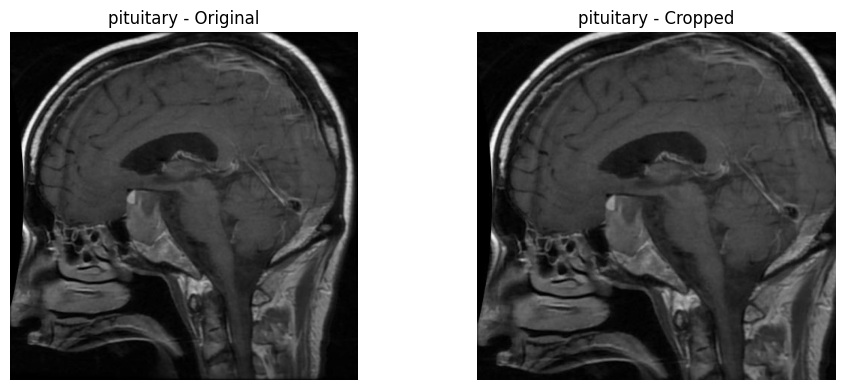

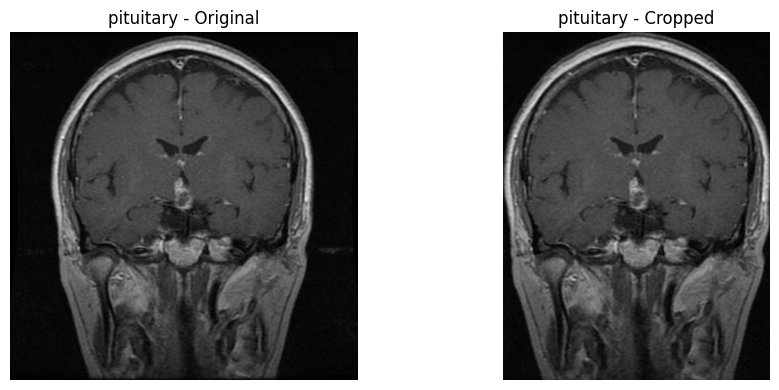

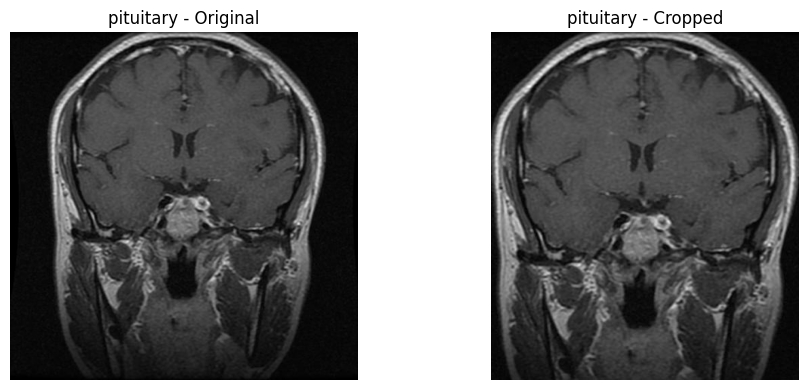

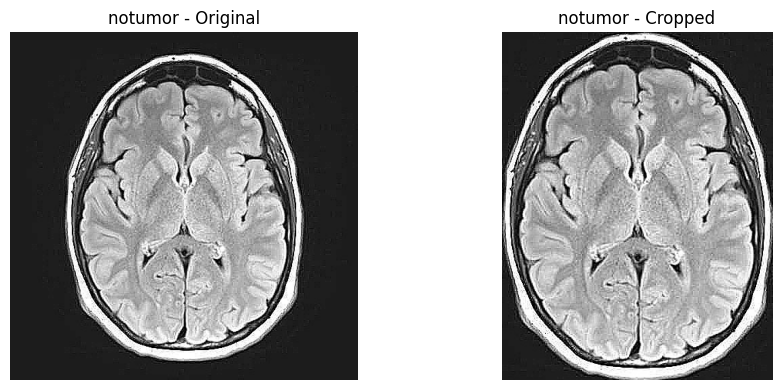

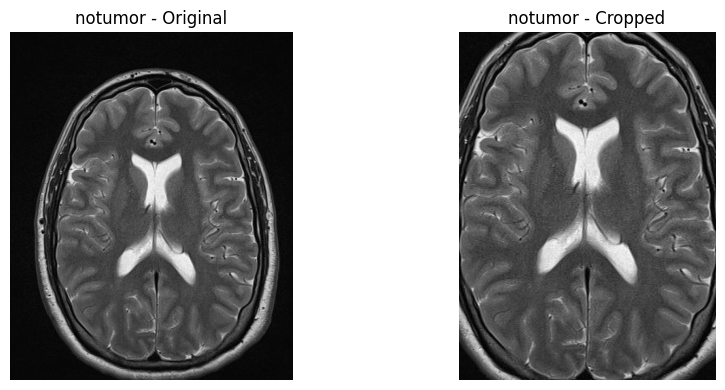

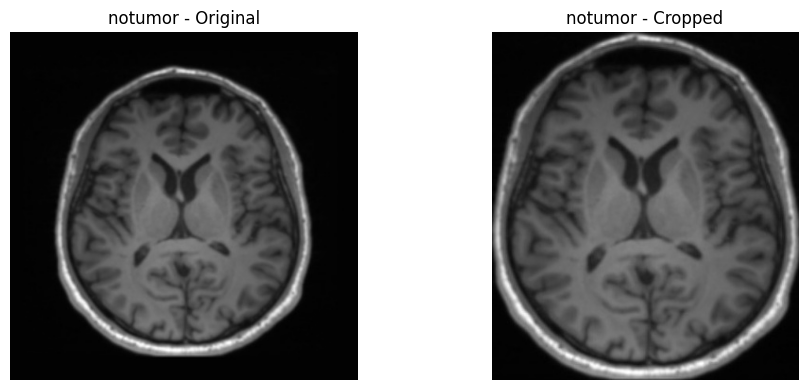

In [13]:
import os
import cv2
import matplotlib.pyplot as plt
import random

original_path = "/Data_set/Data set"
cropped_path = "/Data_set/Cropped"

classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "notumor"
]

split = "Training"

# Number of examples per class
num_examples = 3

for cls in classes:

    original_folder = os.path.join(
        original_path,
        split,
        cls
    )

    cropped_folder = os.path.join(
        cropped_path,
        split,
        cls
    )

    # Get original images
    files = [
        f for f in os.listdir(original_folder)
        if os.path.isfile(os.path.join(original_folder, f))
    ]

    # Randomly select images
    selected_files = random.sample(
        files,
        min(num_examples, len(files))
    )

    for filename in selected_files:

        original_file = os.path.join(
            original_folder,
            filename
        )

        cropped_file = os.path.join(
            cropped_folder,
            filename
        )

        # Read images
        original = cv2.imread(original_file)
        cropped = cv2.imread(cropped_file)

        # Convert BGR → RGB
        original = cv2.cvtColor(
            original,
            cv2.COLOR_BGR2RGB
        )

        cropped = cv2.cvtColor(
            cropped,
            cv2.COLOR_BGR2RGB
        )

        # Display
        plt.figure(figsize=(10, 4))

        plt.subplot(1, 2, 1)
        plt.imshow(original)
        plt.title(f"{cls} - Original")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(cropped)
        plt.title(f"{cls} - Cropped")
        plt.axis("off")

        plt.tight_layout()
        plt.show()

Analyze the cropped images

In [14]:
from PIL import Image
import os
import numpy as np

cropped_path = "/Data_set/Cropped"

classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "notumor"
]


def analyze_cropped_images(split):

    aspect_ratios = []
    widths = []
    heights = []

    for cls in classes:

        folder = os.path.join(
            cropped_path,
            split,
            cls
        )

        for filename in os.listdir(folder):

            filepath = os.path.join(
                folder,
                filename
            )

            try:
                with Image.open(filepath) as img:

                    width, height = img.size

                    widths.append(width)
                    heights.append(height)

                    aspect_ratios.append(
                        width / height
                    )

            except Exception:
                pass

    return (
        widths,
        heights,
        aspect_ratios
    )


for split in ["Training", "Testing"]:

    widths, heights, ratios = analyze_cropped_images(split)

    print("\n" + "=" * 50)
    print(split)
    print("=" * 50)

    print("Number of images:", len(ratios))

    print("Minimum width:", min(widths))
    print("Maximum width:", max(widths))

    print("Minimum height:", min(heights))
    print("Maximum height:", max(heights))

    print("Mean aspect ratio:", np.mean(ratios))
    print("Median aspect ratio:", np.median(ratios))
    print("Standard deviation:", np.std(ratios))

    print("Minimum aspect ratio:", min(ratios))
    print("Maximum aspect ratio:", max(ratios))


Training
Number of images: 5600
Minimum width: 36
Maximum width: 1364
Minimum height: 44
Maximum height: 1413
Mean aspect ratio: 0.8746602788807613
Median aspect ratio: 0.8589108910891089
Standard deviation: 0.12875400785172555
Minimum aspect ratio: 0.22272727272727272
Maximum aspect ratio: 2.4545454545454546

Testing
Number of images: 1600
Minimum width: 36
Maximum width: 724
Minimum height: 44
Maximum height: 708
Mean aspect ratio: 0.8831904069176788
Median aspect ratio: 0.8639892751220779
Standard deviation: 0.13028776474842402
Minimum aspect ratio: 0.5929203539823009
Maximum aspect ratio: 2.4545454545454546


I think aspect ratios are also good

Now we are going to split the dataset

In [15]:
import os
import shutil
from sklearn.model_selection import train_test_split
from tqdm import tqdm

# Cropped dataset
dataset_path = "/Data_set/Cropped"

# Classes
classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "notumor"
]

# Random seed for reproducibility
RANDOM_STATE = 42

# Split ratio
VALIDATION_SIZE = 0.20


for cls in classes:

    # Original cropped training folder
    source_folder = os.path.join(
        dataset_path,
        "Training",
        cls
    )

    # Get image filenames
    files = [
        f for f in os.listdir(source_folder)
        if os.path.isfile(
            os.path.join(source_folder, f)
        )
    ]

    # Split into train and validation
    train_files, val_files = train_test_split(
        files,
        test_size=VALIDATION_SIZE,
        random_state=RANDOM_STATE
    )

    # Create destination folders
    train_folder = os.path.join(
        dataset_path,
        "Train",
        cls
    )

    val_folder = os.path.join(
        dataset_path,
        "Validation",
        cls
    )

    os.makedirs(
        train_folder,
        exist_ok=True
    )

    os.makedirs(
        val_folder,
        exist_ok=True
    )

    # Copy training images
    for filename in tqdm(
        train_files,
        desc=f"Train - {cls}"
    ):

        source = os.path.join(
            source_folder,
            filename
        )

        destination = os.path.join(
            train_folder,
            filename
        )

        shutil.copy2(source, destination)

    # Copy validation images
    for filename in tqdm(
        val_files,
        desc=f"Validation - {cls}"
    ):

        source = os.path.join(
            source_folder,
            filename
        )

        destination = os.path.join(
            val_folder,
            filename
        )

        shutil.copy2(source, destination)


print("\nDataset splitting completed!")

Validation - notumor: 100%|██████████| 280/280 [00:00<00:00, 6286.90it/s]


Dataset splitting completed!


Verify the split

In [16]:
for split in ["Train", "Validation", "Testing"]:

    print("\n" + "=" * 40)
    print(split)
    print("=" * 40)

    for cls in classes:

        folder = os.path.join(
            dataset_path,
            split,
            cls
        )

        count = len([
            f for f in os.listdir(folder)
            if os.path.isfile(
                os.path.join(folder, f)
            )
        ])

        print(f"{cls}: {count}")


Train
glioma: 1120
meningioma: 1120
pituitary: 1120
notumor: 1120

Validation
glioma: 280
meningioma: 280
pituitary: 280
notumor: 280

Testing
glioma: 400
meningioma: 400
pituitary: 400
notumor: 400


Now we are going to resize all images and convert all images in to a RGB and do the normalization and use pretrained DenseNet model to finetune the model for our dataset

In [17]:
import tensorflow as tf
from tensorflow.keras.applications.densenet import preprocess_input

dataset_path = "/Data_set/Cropped"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

# --------------------------------
# Load datasets
# --------------------------------

train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{dataset_path}/Train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{dataset_path}/Validation",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{dataset_path}/Testing",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)


# --------------------------------
# Data Augmentation
# Training data ONLY
# --------------------------------

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    ),
], name="data_augmentation")


# --------------------------------
# Preprocessing / Normalization
# DenseNet121 ImageNet preprocessing
# --------------------------------

def preprocess_train(images, labels):
    images = data_augmentation(images, training=True)
    images = preprocess_input(images)
    return images, labels


def preprocess_val_test(images, labels):
    images = preprocess_input(images)
    return images, labels


# --------------------------------
# Apply preprocessing
# --------------------------------

train_ds = train_ds.map(
    preprocess_train,
    num_parallel_calls=tf.data.AUTOTUNE
)

val_ds = val_ds.map(
    preprocess_val_test,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.map(
    preprocess_val_test,
    num_parallel_calls=tf.data.AUTOTUNE
)


# --------------------------------
# Improve performance
# --------------------------------

train_ds = train_ds.prefetch(tf.data.AUTOTUNE)
val_ds = val_ds.prefetch(tf.data.AUTOTUNE)
test_ds = test_ds.prefetch(tf.data.AUTOTUNE)

Found 4480 files belonging to 4 classes.
Found 1120 files belonging to 4 classes.
Found 1600 files belonging to 4 classes.


In [ ]:
for images, labels in train_ds.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)

Image shape: (32, 224, 224, 3)
Label shape: (32, 4)


Now start Training the model

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import DenseNet121


# ============================================================
# 1. Load Pretrained DenseNet121
# ============================================================

base_model = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)


# ============================================================
# 2. Freeze the DenseNet121 Backbone
# ============================================================

base_model.trainable = False


# ============================================================
# 3. Build the Classification Model
# ============================================================

inputs = layers.Input(shape=(224, 224, 3))

# Feature extraction using pretrained DenseNet121
x = base_model(inputs, training=False)

# Convert feature maps into a single feature vector
x = layers.GlobalAveragePooling2D()(x)

# Reduce overfitting
x = layers.Dropout(0.135545)(x)

# Four output classes
outputs = layers.Dense(
    4,
    activation="softmax"
)(x)

model = Model(inputs, outputs)


# ============================================================
# 4. Display Model Architecture
# ============================================================

model.summary()


# ============================================================
# 5. Compile the Model
# ============================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.00937354
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


# ============================================================
# 6. Callbacks
# ============================================================

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

model_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_densenet121.keras",
    monitor="val_loss",
    save_best_only=True
)


# ============================================================
# 7. Train the Model
# ============================================================

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        early_stopping,
        model_checkpoint
    ]
)


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         4,100 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,041,604 (26.86 MB)

 Trainable params: 4,100 (16.02 KB)

 Non-trainable params: 7,037,504 (26.85 MB)

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 121s 615ms/step - accuracy: 0.7272 - loss: 0.7311 - val_accuracy: 0.8188 - val_loss: 0.5153
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 105s 497ms/step - accuracy: 0.7937 - loss: 0.5719 - val_accuracy: 0.7741 - val_loss: 0.7003
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 70s 499ms/step - accuracy: 0.8170 - loss: 0.5173 - val_accuracy: 0.8420 - val_loss: 0.4368
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 80s 489ms/step - accuracy: 0.8333 - loss: 0.4967 - val_accuracy: 0.7723 - val_loss: 0.7263
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 69s 490ms/step - accuracy: 0.8232 - loss: 0.5297 - val_accuracy: 0.7920 - val_loss: 0.7627
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 82s 493ms/step - accuracy: 0.8413 - loss: 0.4808 - val_accuracy: 0.8304 - val_loss: 0.5218


I think ASHA hyperparameter optimization algorithm is good to get the most right hyperparameters like learning rate and dropout rate

Imports and configuration

In [ ]:
!pip install -q "ray"
import ray
from ray import tune
from ray.tune.schedulers import ASHAScheduler
dataset_path = "/Data_set/Cropped"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

NUM_CLASSES = 4

In [ ]:
import ray

ray.init()

RuntimeError: Maybe you called ray.init twice by accident? This error can be suppressed by passing in 'ignore_reinit_error=True' or by calling 'ray.shutdown()' prior to 'ray.init()'.

In [ ]:
print("Cluster resources:")
print(ray.cluster_resources())

print("\nAvailable resources:")
print(ray.available_resources())

Cluster resources:
{'node:__internal_head__': 1.0, 'CPU': 2.0, 'memory': 9268651213.0, 'node:172.28.0.12': 1.0, 'object_store_memory': 3972279091.0, 'GPU': 1.0, 'accelerator_type:T4': 1.0}

Available resources:
{'node:__internal_head__': 1.0, 'CPU': 2.0, 'object_store_memory': 3972279091.0, 'node:172.28.0.12': 1.0, 'memory': 9268651213.0, 'accelerator_type:T4': 1.0, 'GPU': 1.0}


Create a dataset function

In [ ]:
def create_datasets():

    train_ds = tf.keras.utils.image_dataset_from_directory(
        f"{dataset_path}/Train",
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="categorical",
        shuffle=True,
        seed=SEED
    )

    val_ds = tf.keras.utils.image_dataset_from_directory(
        f"{dataset_path}/Validation",
        image_size=IMG_SIZE,
        batch_size=BATCH_SIZE,
        label_mode="categorical",
        shuffle=False
    )

    # Data augmentation
    data_augmentation = tf.keras.Sequential([
        tf.keras.layers.RandomRotation(0.05),
        tf.keras.layers.RandomZoom(0.10),
        tf.keras.layers.RandomTranslation(
            height_factor=0.05,
            width_factor=0.05
        )
    ])

    # Training preprocessing
    def preprocess_train(images, labels):
        images = data_augmentation(
            images,
            training=True
        )

        images = preprocess_input(images)

        return images, labels

    # Validation preprocessing
    def preprocess_val(images, labels):
        images = preprocess_input(images)

        return images, labels

    # Apply preprocessing
    train_ds = train_ds.map(
        preprocess_train,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    val_ds = val_ds.map(
        preprocess_val,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    # Prefetch
    train_ds = train_ds.prefetch(
        tf.data.AUTOTUNE
    )

    val_ds = val_ds.prefetch(
        tf.data.AUTOTUNE
    )

    return train_ds, val_ds

Build DenseNet121

In [ ]:
def build_model(config):
    import tensorflow as tf
    from tensorflow.keras import layers, Model
    from tensorflow.keras.applications import DenseNet121

    # Pretrained DenseNet121
    base_model = DenseNet121(
        weights="imagenet",
        include_top=False,
        input_shape=(224, 224, 3)
    )

    # Freeze pretrained layers
    base_model.trainable = False

    # Input
    inputs = layers.Input(
        shape=(224, 224, 3)
    )

    # DenseNet
    x = base_model(
        inputs,
        training=False
    )

    # Global Average Pooling
    x = layers.GlobalAveragePooling2D()(x)

    # ASHA controls this value
    x = layers.Dropout(
        config["dropout"]
    )(x)

    # Four classes
    outputs = layers.Dense(
        NUM_CLASSES,
        activation="softmax"
    )(x)

    model = Model(
        inputs=inputs,
        outputs=outputs
    )

    # ASHA controls learning rate
    optimizer = tf.keras.optimizers.Adam(
        learning_rate=config["learning_rate"]
    )

    model.compile(
        optimizer=optimizer,
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model

ASHA training function

In [ ]:
def train_model(config):

    print("\n====================================")
    print("Starting new ASHA trial")
    print("Learning rate:", config["learning_rate"])
    print("Dropout:", config["dropout"])
    print("====================================\n")

    # Create datasets INSIDE the trial
    train_ds, val_ds = create_datasets()

    # Build model
    model = build_model(config)

    MAX_EPOCHS = 10

    for epoch in range(MAX_EPOCHS):

        print(f"\nEpoch {epoch + 1}/{MAX_EPOCHS}")

        history = model.fit(
            train_ds,
            validation_data=val_ds,
            epochs=1,
            verbose=1
        )

        # Validation metrics
        val_loss = history.history["val_loss"][0]

        val_accuracy = history.history[
            "val_accuracy"
        ][0]

        # Send results to ASHA
        tune.report({
            "val_loss":val_loss,
            "val_accuracy":val_accuracy
        })

Define the search space

In [ ]:
search_space = {

    "learning_rate": tune.loguniform(
        1e-4,
        9e-4
    ),

    "dropout": tune.uniform(
        0.1,
        0.5
    )
}

Create ASHA

In [ ]:
asha_scheduler = ASHAScheduler(
    metric="val_accuracy",
    mode="max",
    max_t=10,
    grace_period=3,
    reduction_factor=2
)

Create the tuner

In [ ]:
tuner = tune.Tuner(
     tune.with_resources(
        train_model,
        resources={"cpu":2,"gpu": 1}
    ),
    tune_config=tune.TuneConfig(
        scheduler=asha_scheduler,
        num_samples=15
    ),

    param_space=search_space
)

Start ASHA

In [ ]:
results = tuner.fit()

2026-09-24 11:15:42,242	WARNING callback.py:132 -- The TensorboardX logger cannot be instantiated because either TensorboardX or one of it's dependencies is not installed. Please make sure you have the latest version of TensorboardX installed: `pip install -U tensorboardx`


+--------------------------------------------------------------------+
| Configuration for experiment     train_model_2026-09-24_11-15-39   |
+--------------------------------------------------------------------+
| Search algorithm                 BasicVariantGenerator             |
| Scheduler                        AsyncHyperBandScheduler           |
| Number of trials                 15                                |
+--------------------------------------------------------------------+

View detailed results here: /root/ray_results/train_model_2026-09-24_11-15-39

Trial status: 15 PENDING
Current time: 2026-09-24 11:15:42. Total running time: 0s
Logical resource usage: 2.0/2 CPUs, 1.0/1 GPUs (0.0/1.0 accelerator_type:T4)
+------------------------------------------------------------------+
| Trial name                status       learning_rate     dropout |
+------------------------------------------------------------------+
| train_model_47b47_00000   PENDING        0.000851468  

(pid=33834) 2026-09-24 11:15:47.734367: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
(pid=33834) To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.



Trial train_model_47b47_00000 started with configuration:
+--------------------------------------------------+
| Trial train_model_47b47_00000 config             |
+--------------------------------------------------+
| dropout                                  0.12549 |
| learning_rate                            0.00085 |
+--------------------------------------------------+
(train_model pid=33834) 
(train_model pid=33834) ====================================
(train_model pid=33834) Starting new ASHA trial
(train_model pid=33834) Learning rate: 0.0008514676821197248
(train_model pid=33834) Dropout: 0.1254904222524048
(train_model pid=33834) ====================================
(train_model pid=33834) 
(train_model pid=33834) Found 4480 files belonging to 4 classes.


(train_model pid=33834) 2026-09-24 11:15:52.414329: W tensorflow/core/common_runtime/gpu/gpu_bfc_allocator.cc:47] Overriding orig_value setting because the TF_FORCE_GPU_ALLOW_GROWTH environment variable is set. Original config value was 0.
(train_model pid=33834) WARNING: All log messages before absl::InitializeLog() is called are written to STDERR
(train_model pid=33834) I0000 00:00:1790248552.415817   33911 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13653 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5


(train_model pid=33834) Found 1120 files belonging to 4 classes.


... (130 outputs left out)

(train_model pid=61511) 2026-09-24 12:52:04.976418: I external/local_xla/xla/service/service.cc:163] XLA service 0x797fd0009f30 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
(train_model pid=61511) 2026-09-24 12:52:04.976458: I external/local_xla/xla/service/service.cc:171]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
(train_model pid=61511) 2026-09-24 12:52:05.888383: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
(train_model pid=61511) 2026-09-24 12:52:09.156038: I external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:473] Loaded cuDNN version 91900
(train_model pid=61511) I0000 00:00:1790254342.206502   61600 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


  1/140 ━━━━━━━━━━━━━━━━━━━━ 1:10:16 30s/step - accuracy: 0.2812 - loss: 2.3770
  2/140 ━━━━━━━━━━━━━━━━━━━━ 26s 192ms/step - accuracy: 0.2656 - loss: 2.3310  
  3/140 ━━━━━━━━━━━━━━━━━━━━ 21s 159ms/step - accuracy: 0.2535 - loss: 2.2844
  4/140 ━━━━━━━━━━━━━━━━━━━━ 19s 143ms/step - accuracy: 0.2546 - loss: 2.2237
  5/140 ━━━━━━━━━━━━━━━━━━━━ 34s 254ms/step - accuracy: 0.2549 - loss: 2.1743
  6/140 ━━━━━━━━━━━━━━━━━━━━ 36s 276ms/step - accuracy: 0.2567 - loss: 2.1291
Trial status: 14 TERMINATED | 1 RUNNING
Current time: 2026-09-24 12:52:24. Total running time: 1hr 36min 42s
Logical resource usage: 2.0/2 CPUs, 1.0/1 GPUs (0.0/1.0 accelerator_type:T4)
+------------------------------------------------------------------------------------------------------------------------------+
| Trial name                status         learning_rate     dropout     iter     total time (s)     val_loss     val_accuracy |
+-----------------------------------------------------------------------------------

2026-09-24 12:56:16,308	INFO tune.py:1007 -- Wrote the latest version of all result files and experiment state to '/root/ray_results/train_model_2026-09-24_11-15-39' in 0.0113s.



Trial train_model_47b47_00014 completed after 3 iterations at 2026-09-24 12:56:16. Total running time: 1hr 40min 34s
+--------------------------------------------------+
| Trial train_model_47b47_00014 result             |
+--------------------------------------------------+
| checkpoint_dir_name                              |
| time_this_iter_s                         81.9944 |
| time_total_s                             269.978 |
| training_iteration                             3 |
| val_accuracy                             0.79196 |
| val_loss                                 0.55152 |
+--------------------------------------------------+

Trial status: 15 TERMINATED
Current time: 2026-09-24 12:56:16. Total running time: 1hr 40min 34s
Logical resource usage: 2.0/2 CPUs, 1.0/1 GPUs (0.0/1.0 accelerator_type:T4)
+------------------------------------------------------------------------------------------------------------------------------+
| Trial name                status         learn

I think now is the time for finetunning the Densenet. first train the new classification head, then unfreeze only the later DenseNet layers and train them with a much smaller learning rate.

In [21]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import DenseNet121


# ============================================================
# 1. Load Pretrained DenseNet121
# ============================================================

base_model = DenseNet121(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)


# ============================================================
# 2. Freeze Backbone Initially
# ============================================================

base_model.trainable = False


# ============================================================
# 3. Build Model
# ============================================================

inputs = layers.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.373234)(x)

outputs = layers.Dense(
    4,
    activation="softmax"
)(x)

model = Model(inputs, outputs)


# ============================================================
# 4. Stage 1: Train Classification Head
# ============================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.000638801
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "best_head.keras",
    monitor="val_loss",
    save_best_only=True
)

history_head = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        early_stopping,
        checkpoint
    ]
)


# ============================================================
# 5. Stage 2: Fine-Tune DenseNet121
# ============================================================

base_model.trainable = True

# Freeze most of DenseNet121
# Only the last 50 layers will be trainable

for layer in base_model.layers[:-80]:
    layer.trainable = False

# Last 50 layers are trainable
for layer in base_model.layers[-80:]:
    layer.trainable = True

# Keep BatchNormalization layers frozen
# This is generally safer when fine-tuning with a
# relatively small medical-image dataset.

for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False


# ============================================================
# 6. Recompile with MUCH Smaller Learning Rate
# ============================================================

model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)


# ============================================================
# 8. Fine-Tune
# ============================================================

history_finetune = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15
)


# ============================================================
# 9. Final Model Summary
# ============================================================

model.summary()

Epoch 1/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 95s 514ms/step - accuracy: 0.4641 - loss: 1.3185 - val_accuracy: 0.7268 - val_loss: 0.7214
Epoch 2/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 61s 431ms/step - accuracy: 0.6672 - loss: 0.8193 - val_accuracy: 0.7777 - val_loss: 0.5775
Epoch 3/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 63s 446ms/step - accuracy: 0.7348 - loss: 0.6739 - val_accuracy: 0.8062 - val_loss: 0.5100
Epoch 4/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 61s 433ms/step - accuracy: 0.7667 - loss: 0.6071 - val_accuracy: 0.8062 - val_loss: 0.4979
Epoch 5/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 60s 425ms/step - accuracy: 0.7768 - loss: 0.5834 - val_accuracy: 0.8170 - val_loss: 0.4597
Epoch 6/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 83s 431ms/step - accuracy: 0.7850 - loss: 0.5395 - val_accuracy: 0.8196 - val_loss: 0.4777
Epoch 7/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 61s 435ms/step - accuracy: 0.7924 - loss: 0.5330 - val_accuracy: 0.8196 - val_loss: 0.4517
Epoch 8/10
140/140 ━━━━━━━━━━━━━━━━━━━━ 59s 418ms/step - accuracy: 0.7967 - loss: 0

Model: "functional_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1024)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         4,100 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,203,726 (38.92 MB)

 Trainable params: 1,581,060 (6.03 MB)

 Non-trainable params: 5,460,544 (20.83 MB)

 Optimizer params: 3,162,122 (12.06 MB)

Evaluate performace

50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 84ms/step - accuracy: 0.8581 - loss: 0.4271

OVERALL TEST RESULTS
Test Loss:     0.4271
Test Accuracy: 85.8125%

ACCURACY CHECK
Overall Test Accuracy: 85.8125%

CONFUSION MATRIX
[[299  70  16  15]
 [ 24 292  11  73]
 [  2   7 391   0]
 [  4   5   0 391]]


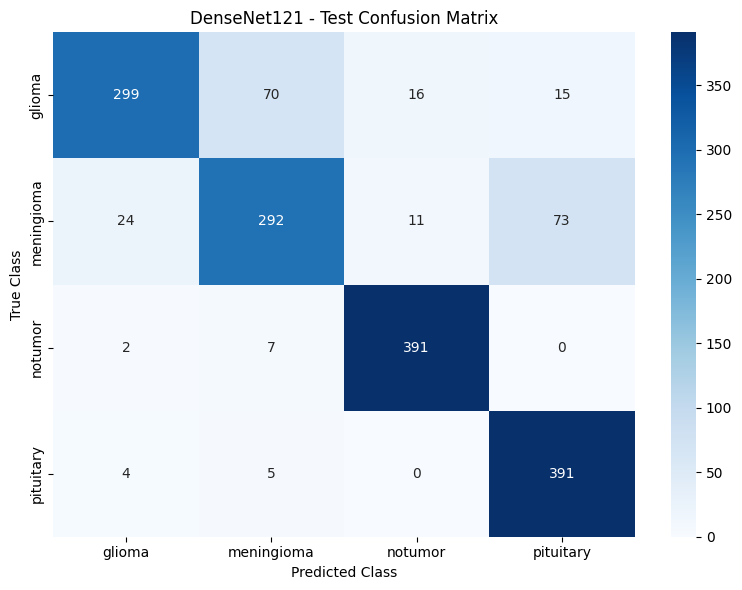


CLASSIFICATION REPORT
              precision    recall  f1-score   support

      glioma     0.9088    0.7475    0.8203       400
  meningioma     0.7807    0.7300    0.7545       400
     notumor     0.9354    0.9775    0.9560       400
   pituitary     0.8163    0.9775    0.8896       400

    accuracy                         0.8581      1600
   macro avg     0.8603    0.8581    0.8551      1600
weighted avg     0.8603    0.8581    0.8551      1600


PREDICTION SUMMARY
Total Test Images: 1600
Correct Predictions: 1373
Incorrect Predictions: 227


In [22]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# ============================================================
# 1. Class names
# ============================================================

class_names = [
    "glioma",
    "meningioma",
    "notumor",
    "pituitary"
]

# ============================================================
# 2. Evaluate model on untouched TEST dataset
# ============================================================

test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

print("\n======================================")
print("OVERALL TEST RESULTS")
print("======================================")
print(f"Test Loss:     {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4%}")

# ============================================================
# 3. Get true labels and predictions
# ============================================================

y_true = []
y_pred = []

for images, labels in test_ds:

    predictions = model.predict(images, verbose=0)

    predicted_classes = np.argmax(predictions, axis=1)
    true_classes = np.argmax(labels.numpy(), axis=1)

    y_true.extend(true_classes)
    y_pred.extend(predicted_classes)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# ============================================================
# 4. Calculate accuracy independently
# ============================================================

overall_accuracy = np.mean(y_true == y_pred)

print("\n======================================")
print("ACCURACY CHECK")
print("======================================")
print(f"Overall Test Accuracy: {overall_accuracy:.4%}")

# ============================================================
# 5. Confusion Matrix
# ============================================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=np.arange(len(class_names))
)

print("\n======================================")
print("CONFUSION MATRIX")
print("======================================")
print(cm)

# ============================================================
# 6. Plot Confusion Matrix
# ============================================================

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.title("DenseNet121 - Test Confusion Matrix")

plt.tight_layout()
plt.show()

# ============================================================
# 7. Classification Report
# ============================================================

print("\n======================================")
print("CLASSIFICATION REPORT")
print("======================================")

print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names,
        digits=4
    )
)

# ============================================================
# 8. Number of correct / incorrect predictions
# ============================================================

correct = np.sum(y_true == y_pred)
incorrect = np.sum(y_true != y_pred)

print("\n======================================")
print("PREDICTION SUMMARY")
print("======================================")
print(f"Total Test Images: {len(y_true)}")
print(f"Correct Predictions: {correct}")
print(f"Incorrect Predictions: {incorrect}")